# Practice notebook: DeepProbLog problems as tididi circuits

This notebook goes with [the practice guide](../docs/practice-guide.md).
The doc has the tutorial, the recipe, the problem statements and **the answers**; this notebook has none.

Run it in this repo's environment (see the README), top to bottom.
For each problem, guess first, build the circuit, then run `check`: it says whether your number matches
a brute-force count, without showing the number.

## Setup: helpers

Every image shows 0, 1 or 2. `var(image, digit)` numbers the switches: image 0 uses 1-3, image 1 uses 4-6,
image 2 uses 7-9. Ordinary facts get numbers after those.

In [13]:
import subprocess
from IPython.display import SVG
from IPython.display import display

def draw(x):
  """Draw a Vtree or Circuit inline."""
  # to_dot(): tididi describes the vtree/circuit in Graphviz text; `dot` turns it into a picture
  svg = subprocess.run(["dot", "-Tsvg"], input=x.to_dot(),
                       capture_output=True, text=True, check=True).stdout
  return SVG(svg)

In [1]:
from collections.abc import Callable
from fractions import Fraction as F
from itertools import product

import tididi
import torch

N = 3  # digits 0, 1, 2

Digits = tuple[int, ...]
Facts = dict[int, bool]
Weights = dict[int, tuple[F, F]]


def show(p: F) -> None:
    """Print a probability as an exact fraction and as a decimal."""
    print(f"{p}  (= {float(p):.4f})")


def todo() -> None:
    raise NotImplementedError("TODO: fill in this cell")


def var(image: int, digit: int) -> int:
    """Switch variable for "image shows digit"."""
    return 1 + image * N + digit


def exactly_one(vt: tididi.Vtree, variables: list[int]) -> tididi.Circuit:
    """At least one is true, and no two are true together."""
    f = tididi.clause(vt, variables)                  # circuit: "at least one of these is true" (an OR)
    for i, a in enumerate(variables):
        for b in variables[i + 1:]:
            f = f & tididi.clause(vt, [-a, -b])       # & AND with circuit "not (a and b)": no two on together
    return f


def digit_vtree(images: int, extra: tuple[int, ...] = ()) -> tididi.Vtree:
    """One vtree group per image, then one leaf per extra fact variable."""
    # A vtree is only the layout: which variables exist and how they are grouped. No logic.
    vt = tididi.Vtree.balanced_over([var(0, d) for d in range(N)])   # a group of image 0's switches
    for image in range(1, images):
        # join(left, right): a new root with the vtree so far on the left and this image's group on the right
        vt = tididi.Vtree.join(vt, tididi.Vtree.balanced_over([var(image, d) for d in range(N)]))
    for variable in extra:
        vt = tididi.Vtree.join(vt, tididi.Vtree.leaf(variable))      # leaf: a one-variable vtree
    return vt


def domain(vt: tididi.Vtree, images: int) -> tididi.Circuit:
    """Every image shows exactly one digit."""
    f = tididi.one(vt)                                # circuit "true": every world allowed
    for image in range(images):
        f = f & exactly_one(vt, [var(image, d) for d in range(N)])   # keep worlds where this image shows one digit
    return f


def where(vt: tididi.Vtree, images: int, condition: Callable[[Digits], bool]) -> tididi.Circuit:
    """OR of one cube per digit combination where condition holds. No domain: add it last."""
    # One cube per matching digits tuple, e.g. (0, 2) -> cube(vt, [1, 6]): circuit
    # "switch 1 on AND switch 6 on". Every switch a cube does not name is free.
    cubes = [tididi.cube(vt, [var(image, d) for image, d in enumerate(digits)])
             for digits in product(range(N), repeat=images) if condition(digits)]
    # or_many: one circuit, "any of these cubes". zero(vt): circuit "false" (no worlds) if nothing matched.
    return tididi.or_many(cubes) if cubes else tididi.zero(vt)


def digit_weights(probs: list[list[F]]) -> Weights:
    """Switch weights: off 1, on p."""
    # tididi weights are {variable: (weight when false, weight when true)}, one entry per vtree variable
    return {var(image, d): (F(1), p) for image, ps in enumerate(probs) for d, p in enumerate(ps)}


def fact_weights(facts: dict[int, F]) -> Weights:
    """Ordinary-fact weights: (1 - p, p)."""
    return {variable: (1 - p, p) for variable, p in facts.items()}


def brute_force(condition: Callable[[Digits, Facts], bool], digit_probs: list[list[F]],
                fact_probs: dict[int, F]) -> F:
    """Sum of world probabilities where condition(digits, facts) holds."""
    names = list(fact_probs)
    total = F(0)
    for digits in product(range(N), repeat=len(digit_probs)):
        for values in product([False, True], repeat=len(names)):
            facts = dict(zip(names, values))
            p = F(1)
            for image, d in enumerate(digits):
                p *= digit_probs[image][d]
            for name, value in facts.items():
                p *= fact_probs[name] if value else 1 - fact_probs[name]
            if condition(digits, facts):
                total += p
    return total


def check(value: F, condition: Callable[[Digits, Facts], bool], digit_probs: list[list[F]],
          fact_probs: dict[int, F] | None = None,
          given: Callable[[Digits, Facts], bool] | None = None) -> None:
    """Say whether value equals P(condition | given) by brute force, without printing it."""
    fact_probs = fact_probs or {}
    expected = brute_force(condition, digit_probs, fact_probs)
    if given is not None:
        expected = (brute_force(lambda d, f: condition(d, f) and given(d, f), digit_probs, fact_probs)
                    / brute_force(given, digit_probs, fact_probs))
    print("matches brute force" if value == expected else "does NOT match brute force")


IMAGE1 = [F("0.7"), F("0.2"), F("0.1")]
IMAGE2 = [F("0.1"), F("0.8"), F("0.1")]
IMAGE3 = [F("0.3"), F("0.3"), F("0.4")]

## tididi tutorial

Run these alongside the doc's tutorial section.

In [15]:
# 1-2. A vtree, literals and the operators
vt = tididi.Vtree.balanced(3)                 # vtree (layout only) over variables 1, 2, 3
# literal(vt, 1): circuit "x1 is true"   literal(vt, -2): circuit "x2 is false"   (minus = false)
# &: AND, worlds in both                 |: OR, worlds in either
f = (tididi.literal(vt, 1) & tididi.literal(vt, -2)) | tididi.literal(vt, 3)
print("vtree variables:", vt.variables)       # the variables the vtree holds
print("models of f:", f.model_count())        # how many of the 2**3 = 8 worlds make f true
print("one model:", f.satisfying_assignment())   # one such world, as Literal(variable, value) pairs

vtree variables: [1, 2, 3]
models of f: 5
one model: [Literal(1, True), Literal(2, False), Literal(3, True)]


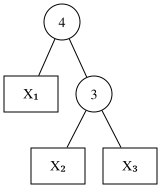

4
a consumed? False   b consumed? True
using b again: Circuit has been consumed. Copy it before passing it to a consuming operation.


In [18]:
# 3. Operations consume their inputs; copy() keeps one
a = tididi.literal(vt, 1)        # circuit "x1 is true"
b = tididi.literal(vt, 2)        # circuit "x2 is true"

# & uses up (consumes) both inputs. a.copy() hands over a copy, so a survives; b is used up.
both = a.copy() & b              # circuit "x1 AND x2"
print("a consumed?", a.is_consumed, "  b consumed?", b.is_consumed)
try:
    b.model_count()              # b was consumed, so this raises
except tididi.ConsumedCircuitError as error:
    print("using b again:", error)

In [ ]:
# 4-5. Free variables count, and weights need every variable
x = tididi.literal(vt, 1)        # circuit "x1 is true"; x2 and x3 are free
print("models of x over 3 variables:", x.model_count())   # 2 free variables -> 2**2 = 4 worlds

alarm = tididi.literal(vt, 1) | tididi.literal(vt, 2)    # circuit "x1 OR x2"
# weights: {variable: (weight when false, weight when true)}. Every vtree variable needs one,
# even variable 3, which alarm never mentions.
weights = {1: (F("0.9"), F("0.1")), 2: (F("0.8"), F("0.2")), 3: (F("0.5"), F("0.5"))}
# weighted_count: for each world of alarm, multiply its variables' weights; add up those products
show(alarm.weighted_count(weights))
show(alarm.weighted_count(weights | {3: (1, 1)}))   # free variable 3 now weighs 2
try:
    alarm.weighted_count({1: (F("0.9"), F("0.1"))})   # weights for 2 and 3 missing -> ValueError
except ValueError as error:
    print("missing weights:", error)

In [ ]:
# 7. An algebra that prints the arithmetic a circuit does
# An algebra tells evaluate() what to do at each part of the circuit. tididi walks the circuit
# bottom-up and calls these four methods; here they build a string instead of a number.
class Trace:
    def zero(self) -> str:                  # value of "false"
        return "0"

    def leaf(self, variable: int, sign: bool | None) -> str:   # one variable: sign True/False, None = free
        return f"w({variable},{sign})"

    def add(self, a: str, b: str) -> str:   # combine alternative branches (an OR)
        return f"({a} + {b})"

    def mul(self, a: str, b: str) -> str:   # combine the left and right sides of a vtree split (an AND)
        return f"{a}*{b}"


print(tididi.literal(vt, 1).evaluate(Trace()))   # run Trace over circuit "x1 is true"

## Worked examples

Full code; the doc explains each result.

In [ ]:
# Example 1: addition. P(digit1 + digit2 = 2)
vt = digit_vtree(2)              # vtree: image 1's switches (1-3) on one side, image 2's (4-6) on the other
# circuit: (cube 0+2 OR cube 1+1 OR cube 2+0) AND (each image shows exactly one digit)
sum_is_2 = where(vt, 2, lambda d: d[0] + d[1] == 2) & domain(vt, 2)
weights = digit_weights([IMAGE1, IMAGE2])   # switch weights: (off 1, on p)
show(sum_is_2.weighted_count(weights))      # P(sum = 2)
# model_count: worlds allowed; pair_count: circuit size (stored child pairs)
print("worlds:", sum_is_2.model_count(), " size:", sum_is_2.pair_count(), "pairs")
check(sum_is_2.weighted_count(weights), lambda d, f: d[0] + d[1] == 2, [IMAGE1, IMAGE2])

In [ ]:
# Example 2: a comparison. P(digit1 < digit2)
less_than = where(vt, 2, lambda d: d[0] < d[1]) & domain(vt, 2)   # same recipe, new condition
show(less_than.weighted_count(weights))

In [ ]:
# Example 3: evidence. P(digit1 = 0 | sum = 2)
first_is_0 = tididi.literal(vt, var(0, 0))   # circuit "switch 1 on": image 1 shows 0
# AND the two (copy keeps sum_is_2 usable), then weigh: P(sum = 2 and digit1 = 0)
joint = (sum_is_2.copy() & first_is_0).weighted_count(weights)
show(joint / sum_is_2.weighted_count(weights))   # divide by P(sum = 2) -> the conditional

# Another way: an evaluator takes evidence without building a new circuit. It consumes its circuit.
ev = sum_is_2.copy().evaluator(weights)
ev.observe([var(0, 0)])              # evidence: switch 1 is on
show(ev.value())                     # the joint, P(sum = 2 and digit1 = 0)

In [ ]:
# Example 4: training through the circuit
# The same kind of algebra as Trace, but with torch tensors, so gradients flow back to the logits.
class TorchProbability:
    """tididi algebra over tensors: switch on -> p, off -> 1, free -> 1 + p."""

    def __init__(self, probs: torch.Tensor):   # probs[image, digit]
        self.probs = probs

    def zero(self) -> torch.Tensor:
        return torch.tensor(0.0)

    def leaf(self, variable: int, sign: bool | None) -> torch.Tensor:
        image, digit = divmod(variable - 1, N)
        p = self.probs[image, digit]
        if sign is None:                 # free switch: off weight + on weight
            return 1 + p
        return p if sign else torch.tensor(1.0)

    def add(self, a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
        return a + b

    def mul(self, a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
        return a * b


logits = torch.tensor([[2.0, 0.7, 0.0], [0.0, 2.1, 0.0]], requires_grad=True)
p = less_than.evaluate(TorchProbability(logits.softmax(dim=1)))   # run the circuit's arithmetic in torch
loss = -p.log()
loss.backward()
print("P(digit1 < digit2) =", round(p.item(), 4))
print("gradients:\n", logits.grad)
with torch.no_grad():
    logits -= 0.5 * logits.grad
print("after one step:", round(less_than.evaluate(TorchProbability(logits.softmax(dim=1))).item(), 4))

## Problems

The statements are in the doc. Replace each `todo()` with your code. `vt`, `weights`, `sum_is_2`,
`less_than` and `TorchProbability` from the examples are still available.

In [ ]:
# Problem 1: P(digit1 * digit2 = 0), images 1 and 2
product_0 = todo()
show(product_0.weighted_count(weights))
check(product_0.weighted_count(weights), lambda d, f: d[0] * d[1] == 0, [IMAGE1, IMAGE2])

In [ ]:
# Problem 2: P(digit1 + digit2 + digit3 = 3), images 1, 2 and 3. Guess the number of worlds first.
vt3 = digit_vtree(3)             # vtree: one group per image, 3 images (switches 1-9)
sum3 = todo()
weights3 = digit_weights([IMAGE1, IMAGE2, IMAGE3])
show(sum3.weighted_count(weights3))
print("worlds:", sum3.model_count())
check(sum3.weighted_count(weights3), lambda d, f: sum(d) == 3, [IMAGE1, IMAGE2, IMAGE3])

In [ ]:
# Problem 3: P(digit1 = 2 | digit1 + digit2 = 3)
answer3 = todo()
show(answer3)
check(answer3, lambda d, f: d[0] == 2, [IMAGE1, IMAGE2], given=lambda d, f: d[0] + d[1] == 3)

In [ ]:
# Problem 4: P(reported_even), with 0.2::typo as variable 7
TYPO = 7
vt4 = digit_vtree(2, extra=(TYPO,))   # 2 image groups plus a leaf for variable 7
reported_even = todo()
weights4 = todo()
show(reported_even.weighted_count(weights4))
check(reported_even.weighted_count(weights4),
      lambda d, f: ((d[0] + d[1]) % 2 == 0) != f[TYPO], [IMAGE1, IMAGE2], {TYPO: F("0.2")})

In [ ]:
# Problem 5: P(exactly one cat), cat_net gives 0.9 (variable 1) and 0.3 (variable 2)
vt5 = tididi.Vtree.balanced(2)   # vtree over variables 1 and 2
one_cat = todo()
weights5 = todo()
show(one_cat.weighted_count(weights5))
check(one_cat.weighted_count(weights5), lambda d, f: f[1] != f[2], [], {1: F("0.9"), 2: F("0.3")})

# Then try the switch weights (1, p) instead. What do you get, and why is it wrong?

In [ ]:
# Problem 6: find the bug. Predict first: too big or too small? How many worlds?
vt = digit_vtree(2)
# one cube per a: circuit "image 1 shows a AND image 2 shows 2 - a"; unnamed switches are free
worlds = [tididi.cube(vt, [var(0, a), var(1, 2 - a)]) for a in range(3)]
# or_many: "any of these cubes"; & exactly_one(vt, switches): AND "exactly one of these switches is on"
buggy = tididi.or_many(worlds) & exactly_one(vt, [var(0, d) for d in range(N)])
show(buggy.weighted_count(weights))
print("worlds:", buggy.model_count())

fixed = todo()
check(fixed.weighted_count(weights), lambda d, f: d[0] + d[1] == 2, [IMAGE1, IMAGE2])

In [ ]:
# Problem 7: the most likely explanation of sum = 2. Values are (weight, assignment) pairs.
class MaxProduct:
    def __init__(self, weights: Weights):
        self.weights = weights

    def zero(self) -> tuple[F, tuple]:
        todo()

    def leaf(self, variable: int, sign: bool | None) -> tuple[F, tuple]:
        todo()   # don't forget sign None: a free variable

    def add(self, a: tuple, b: tuple) -> tuple:
        todo()

    def mul(self, a: tuple, b: tuple) -> tuple:
        todo()


sum_is_2 = where(vt, 2, lambda d: d[0] + d[1] == 2) & domain(vt, 2)
best, assignment = sum_is_2.evaluate(MaxProduct(weights))   # run your algebra over the circuit
print(best, [variable for variable, on in assignment if on])

In [ ]:
# Problem 8: two labels for the same pair, from uniform probabilities
less_than = where(vt, 2, lambda d: d[0] < d[1]) & domain(vt, 2)
logits = torch.zeros(2, 3, requires_grad=True)
optimizer = torch.optim.SGD([logits], lr=1.0)
for step in range(200):
    probs = logits.softmax(dim=1)
    loss = todo()   # -log P(sum = 2) - log P(digit1 < digit2)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
print(logits.softmax(dim=1))

# Part 2: train from zeros on -log P(sum = 2) alone. What happens, and why?

In [ ]:
# Problem 9: does the vtree matter? 10 digits per image: image 1 uses 1-10, image 2 uses 11-20.
def var10(image: int, digit: int) -> int:
    return 1 + image * 10 + digit


grouped = todo()       # Vtree.join of one group per image
interleaved = todo()   # Vtree.linear: image 1 digit 0, image 2 digit 0, image 1 digit 1, ...


def total_pairs(vt: tididi.Vtree) -> int:
    """Sum of pair_count() over the 19 sum circuits, each with the domain."""
    todo()


print("grouped:", total_pairs(grouped), "  interleaved:", total_pairs(interleaved))